# [Open in Colab](https://colab.research.google.com/github/dmochow/BME-i9400-2026/blob/main/labs/lab01_regression.ipynb)

# BME i9400 — Lab 1
## A Regression Baseline for Body Fat

**Fall 2026 · Released Monday, October 5 · Notebook due Tuesday, October 14, 11:59 AM EST · Defense quiz Wednesday, October 14, in class**

In this lab you carry out a complete regression study on your own: prepare a dataset, fit and
regularise a linear model, choose between models on validation data, evaluate the choice once on a
test set, and report the result. The methods are those of Meetings 6 and 7. The dataset is new.

**How the lab is assessed.** The lab component of the course is 20% of the grade, over three labs.
Within a lab, the in-class defense quiz counts 70% and the submitted notebook 30%.

- **The notebook** is graded on whether it runs from top to bottom without error, whether every task
  is complete and correct, and on the quality of the report in section 8.
- **The defense quiz** is a ten-minute written quiz at the start of Meeting 10, taken closed-book: no
laptop, no notes, no AI tools. It asks you to explain and justify what is in *your* notebook: why a step was taken, what a
  number means, what would have happened otherwise. Section 9 describes it.

**Generative AI is permitted and expected** on the notebook. Use it as you would in practice: to
write code, to debug, to check your understanding. You are responsible for every line you submit,
and the defense tests whether you can account for it without assistance. Record how you used AI in
section 9.

**Work individually.** Discussion of approach is encouraged; code and text must be your own.

---
## 1 — The question and the data

Body fat percentage is a measure of health that is difficult to measure directly. The reference
method in this dataset is underwater weighing: the subject is weighed in air and fully submerged,
body density is computed from the two weights, and body fat is estimated from density by Siri's
equation,

$$\text{body fat (\%)} = \frac{495}{\text{density}} - 450$$

Underwater weighing needs a tank, trained staff, and a cooperative subject. A tape measure and a
scale need none of these. The question of this lab is the question of Penrose, Nelson and Fisher
(*Medicine & Science in Sports & Exercise*, 1985): **how well can body fat be predicted from
circumference measurements, weight, height, and age?**

### The data

252 men, measured at the Human Performance Research Center, Brigham Young University; the data were
made public by Johnson, "Fitting Percentage of Body Fat to Simple Body Measurements", *Journal of
Statistics Education*, 1996, with permission for non-commercial use. The course copy is
`data/bodyfat.csv`, one row per man.

| Column | Meaning | Units |
|---|---|---|
| `case` | identifier, 1 to 252 | |
| `body_fat_pct` | **the target**: body fat from Siri's equation | % |
| `density` | body density from underwater weighing | g/cm³ |
| `age` | age | years |
| `weight_lb` | weight | pounds |
| `height_in` | height | inches |
| `bmi` | body mass index, computed from weight and height | kg/m² |
| `neck`, `chest`, `abdomen`, `hip`, `thigh`, `knee`, `ankle`, `biceps`, `forearm`, `wrist` | circumferences | cm |

The documentation that accompanies the data states that it is "as received" and contains "a few
errors". Finding them is part of section 2.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

URL  = "https://raw.githubusercontent.com/dmochow/BME-i9400-2026/main/data/bodyfat.csv"
data = pd.read_csv(URL)

circumferences = ["neck", "chest", "abdomen", "hip", "thigh", "knee", "ankle", "biceps", "forearm", "wrist"]
measurements   = ["age", "weight_lb", "height_in", "bmi"] + circumferences      # everything a clinic can measure
target         = "body_fat_pct"

print(f"{len(data)} men, {data.shape[1]} columns")
data.describe().T[["mean", "std", "min", "max"]].round(2)

252 men, 17 columns


,mean,std,min,max
case,126.50,72.89,1.0,252.00
body_fat_pct,19.15,8.37,0.0,47.50
density,1.06,0.02,1.0,1.11
age,44.88,12.60,22.0,81.00
weight_lb,178.92,29.39,118.5,363.15
height_in,70.15,3.66,29.5,77.75
bmi,25.44,3.65,18.1,48.90
neck,37.99,2.43,31.1,51.20
chest,100.82,8.43,79.3,136.20
abdomen,92.56,10.78,69.4,148.10


---
## 2 — Data readiness

Before any model is fitted, two questions from Meeting 1: are the values plausible, and is every
column one that would be available when the model is used?

### 2.1 Implausible values

The summary table above already shows at least two impossible values. Write code that finds every
row in which **height is below 50 inches** or **body fat is at most 0%**, and look at those rows in
full. Then decide what to do with each one — correct it, remove it, or keep it — and state the
decision and the reason in the answer cell. A decision without a reason receives no credit.

> Removing a row because it is inconvenient is not a reason. A value that is physically impossible,
> or that the documentation identifies as a recording error, is. The `bmi` column, which was
> computed from weight and height before the error was made, is evidence about what the height
> should have been.

In [4]:
# --- TODO: find the implausible rows ---
suspect = data[(data["height_in"] < 50) | (data["body_fat_pct"] <= 0)] # a DataFrame: the rows with height_in < 50 or body_fat_pct <= 0

suspect

assert suspect is not None, "Fill in suspect."
assert len(suspect) >= 2 and ((suspect["height_in"] < 50) | (suspect["body_fat_pct"] <= 0)).all(), \
    "suspect should hold exactly the rows that meet one of the two conditions."
suspect

,case,body_fat_pct,density,age,weight_lb,height_in,bmi,neck,chest,abdomen,hip,thigh,knee,ankle,biceps,forearm,wrist
41,42,32.9,1.0250,44,205.0,29.5,29.9,36.6,106.0,104.3,115.5,70.6,42.5,23.7,33.6,28.7,17.4
181,182,0.0,1.1089,40,118.5,68.0,18.1,33.8,79.3,69.4,85.0,47.2,33.5,20.2,27.7,24.6,16.5


In [5]:
# --- TODO: apply your decisions, producing the DataFrame `clean` ---
# For a row you correct, change the value; for a row you remove, drop it; for a row you keep, do nothing.
clean = data.copy()
clean.loc[clean["height_in"] < 50, "height_in"] = 69.5
clean = clean[clean["body_fat_pct"] > 0].copy()



assert clean is not None, "Produce the DataFrame clean."
assert set(clean.columns) == set(data.columns) and len(clean) <= len(data), "clean should keep the same columns."
print(f"{len(clean)} men remain after your decisions ({len(data) - len(clean)} removed)")

251 men remain after your decisions (1 removed)


**Answer 2.1** — For each row you flagged: what is wrong, what you did, and why.


I flaggged case 42 and case 182. This is because for case 42 a 205-lb adult man cannot be 29.5 in tall, so the value is physically impossible and needs to be corrected. The bmi column (29.9 kg/m²) was computed from the true height before the error was made. Solving BMI = weight / height² for height gives about 69.4 in, consistent with with being arounf 69.5 in. For case 182 having z body fat is impossible. The error is in the measurement itself: the recorded density, 1.1089 g/cm³, gives 495/1.1089 − 450 = −3.6% by Siri’s equation, which is also impossible. Here, nothing in the row tells us what the true body fat was, so the target can't be corrected and the row is removed.

### 2.2 The column that must not be used

One column in this file is not a measurement a clinic could take with a scale and a tape measure,
and it is related to the target by a formula. Identify it, and demonstrate what happens when it is
included as a feature: fit a least squares model on all 14 measurements with and without that
column, on the full cleaned dataset, and compare the two values of $R^2$.

> Using a feature that is computed from the target, or that would only be known once the target is
> known, is called **target leakage**. The resulting model looks excellent and is useless, because
> the feature will not exist when the model is applied to a new person. Leakage of this kind is one
> of the most common ways in which a published model fails in practice (Meeting 1).

In [6]:
from sklearn.linear_model import LinearRegression

leaky_column = "density"          # TODO: the name of the column

# --- TODO: fit on the 14 measurements plus the leaky column, and on the 14 measurements alone ---
r2_with    = LinearRegression().fit(clean[measurements + [leaky_column]], clean[target]
).score(clean[measurements + [leaky_column]], clean[target])            # R^2 on the data used for fitting, with the leaky column

r2_without = LinearRegression().fit(clean[measurements], clean[target]
).score(clean[measurements], clean[target])            # ... without it

assert leaky_column is not None, "Fill in leaky_column."
assert leaky_column in clean.columns and leaky_column not in measurements + ["case", target], \
    "Name the column that is neither a clinic measurement, nor the identifier, nor the target."
assert r2_with is not None and r2_without is not None, "Fit both models."
print(f"R^2 with {leaky_column}: {r2_with:.3f}     without: {r2_without:.3f}")
assert r2_with > 0.95 > r2_without, "Including the leaky column should make the fit nearly perfect."

R^2 with density: 0.979     without: 0.745


**Answer 2.2** — Which column leaks, why (cite the formula), and why a model that used it would fail in a
clinic.


The density columnn leaks the target. Body fat is computed from it by Siri’s equation, body fat = 495/density − 450, so a linear model can reproduce body fat almost exactly from density. R² rises from 0.745 without it to 0.979 with it. It is not exactly 1 because the relation is in 1/density rather than linear, and because a few rows contain recording errors. Also, density comes from underwater weighing, which is exactly the expensive procedure this model is meant to replace. A clinic with only a scale and a tape measure would not have density for a new patient. The model could not be applied, and the high R² says nothing about how well circumferences predict body fat.

---
## 3 — Splitting the data

Three sets are needed: a **training set** to fit weights, a **validation set** to choose between
models and to choose $\lambda$, and a **test set** that is touched exactly once, in section 7.

> The training and validation sets together are called the **development set**: everything that may
> be used while the model is being built.

The test split is fixed below so that every student's test set is the same 63 men. The validation
split inside the development set is yours to make; use a fixed `random_state` so that your notebook
is reproducible.

In [7]:
from sklearn.model_selection import train_test_split

X_all = clean[measurements].values
y_all = clean[target].values

# Done for you: the test set, 25% of the men, identical for every student.
X_dev, X_test, y_dev, y_test = train_test_split(X_all, y_all, test_size=0.25, random_state=9400)

# --- TODO: split the development set into training and validation sets (about 25% validation) ---
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=9400)



assert X_train is not None, "Make the validation split."
assert len(X_train) + len(X_val) == len(X_dev) and len(X_val) >= 0.2 * len(X_dev), \
    "Validation should be about a quarter of the development set."
print(f"training {len(y_train)}   validation {len(y_val)}   test {len(y_test)}")
print(f"body fat in the training set: mean {y_train.mean():.1f}%, standard deviation {y_train.std(ddof=1):.1f}%")

training 141   validation 47   test 63
body fat in the training set: mean 19.6%, standard deviation 7.9%


---
## 4 — The least squares baseline

Fit ordinary least squares on all 14 measurements, by the normal equations or with
`LinearRegression` (if you use both, verify that they agree). Report:

- RMSE and $R^2$ on the training and validation sets, in units of body fat percentage points
- the RMSE of the model that predicts the training mean for everyone, which any model must beat
- the fitted weights, each with its units (percentage points of body fat per year, per pound, per
  inch, per kg/m², per centimetre)
- a plot of the residuals against the fitted values on the training set

Then read the weights. Several have signs opposite to the correlation of their feature with body
fat. Compute the correlation matrix of the 14 measurements and use it to explain why, in the answer
cell (Meeting 7, section 4).

predict-the-mean baseline, validation RMSE: 9.08 percentage points
least squares:  training RMSE 3.88  R^2 0.758   |   validation RMSE 4.51  R^2 0.747
Intercept: -133.85804705039783 percentage points
age: 0.0511
weight_lb: -0.4413
height_in: 1.3038
bmi: 1.7251
neck: -0.0539
chest: 0.0225
abdomen: 1.0677
hip: -0.3140
thigh: 0.5000
knee: 0.0901
ankle: -0.0622
biceps: 0.2547
forearm: 0.4361
wrist: -1.4239


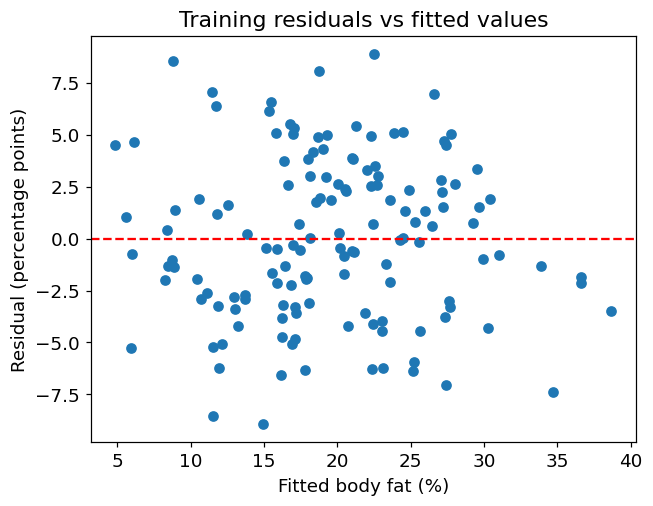

height_in   -0.034
ankle        0.254
age          0.291
wrist        0.335
forearm      0.349
neck         0.483
biceps       0.487
knee         0.499
thigh        0.550
weight_lb    0.605
hip          0.618
chest        0.696
bmi          0.722
abdomen      0.810
Name: body_fat_pct, dtype: float64


In [8]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def r_squared(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - y_true.mean())**2)

# --- TODO: fit least squares on all 14 measurements ---
ols            = LinearRegression()
ols.fit(X_train, y_train)    # the fitted model, or the weight vector from the normal equations

pred_train_ols = ols.predict(X_train)
pred_val_ols   = ols.predict(X_val)

assert pred_train_ols is not None and pred_val_ols is not None, "Fit the model and predict both sets."
baseline_rmse = rmse(y_val, np.full_like(y_val, y_train.mean(), dtype=float))
print(f"predict-the-mean baseline, validation RMSE: {baseline_rmse:.2f} percentage points")
print(f"least squares:  training RMSE {rmse(y_train, pred_train_ols):.2f}  R^2 {r_squared(y_train, pred_train_ols):.3f}"
      f"   |   validation RMSE {rmse(y_val, pred_val_ols):.2f}  R^2 {r_squared(y_val, pred_val_ols):.3f}")
assert rmse(y_val, pred_val_ols) < baseline_rmse, "The model should beat the mean."

# --- TODO: print each weight with its units; plot residuals against fitted values; show the correlations ---
print("Intercept:", ols.intercept_, "percentage points")

for name, weight in zip(measurements, ols.coef_):
    print(f"{name}: {weight:.4f}")

plt.figure()
plt.scatter(pred_train_ols, y_train - pred_train_ols)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted body fat (%)")
plt.ylabel("Residual (percentage points)")
plt.title("Training residuals vs fitted values")
plt.show()

correlations = clean[measurements + [target]].corr()
print(correlations[target].drop(target).sort_values().round(3))

**Answer 4** — Which weights have a sign opposite to their feature's correlation with body fat, and why.



The weights that have a sign opposite to their feature's correlation with body fat are weight: −0.44 pp/lb, correlation +0.57; wrist: −1.42 pp/cm, correlation +0.35; hip: −0.31 pp/cm, correlation +0.56; height: +1.30 pp/in, correlation −0.07; neck (−0.05 pp/cm) and ankle (−0.06 pp/cm), both near zero. A correlation is a marginal relationship so heavier men tend to be fatter and a regression weight is a partial effect so the change in predicted body fat when one feature increases with all the others held fixed. The correlation matrix shows the measurements are strongly collinear. Weight correlates 0.92 with BMI, 0.90 with abdomen and 0.95 with hip.

For Weight with abdomen, hip and BMI held fixed, extra weight has to be lean mass (muscle and bone), so it predicts less fat. Looking at the wrist circumference is mostly bone and measures skeletal frame. At the same abdominal girth, a bigger-framed man is leaner.
With weight, height and BMI, these 3 are tied together by the BMI formula. Least squares can trade large opposite-signed weights among them with almost no change in the fit, which is why height gets a large positive weight despite a correlation near zero.

---
## 5 — Ridge regression

Standardise the 14 measurements with the **training-set** mean and standard deviation, fit ridge
regression over a grid of $\lambda$ (`sklearn.linear_model.Ridge(alpha=...)`, or your own
implementation from Meeting 7), and:

- plot the validation RMSE against $\lambda$ on a logarithmic axis, and report the $\lambda$ that
  minimises it
- plot the weights against $\lambda$ (the coefficient paths), and say which weights the penalty
  shrinks first and why

> `Ridge(alpha=λ)` uses the convention of Meeting 7: a penalty on the weights, none on the intercept.

best lambda: 1.33    validation RMSE there: 4.46    (least squares: 4.51)


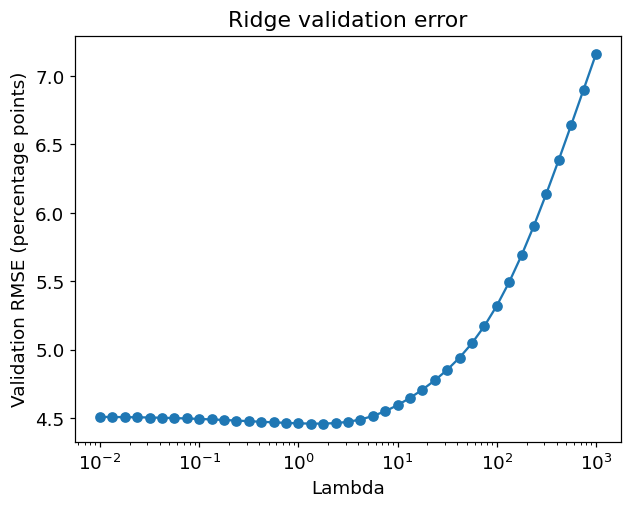

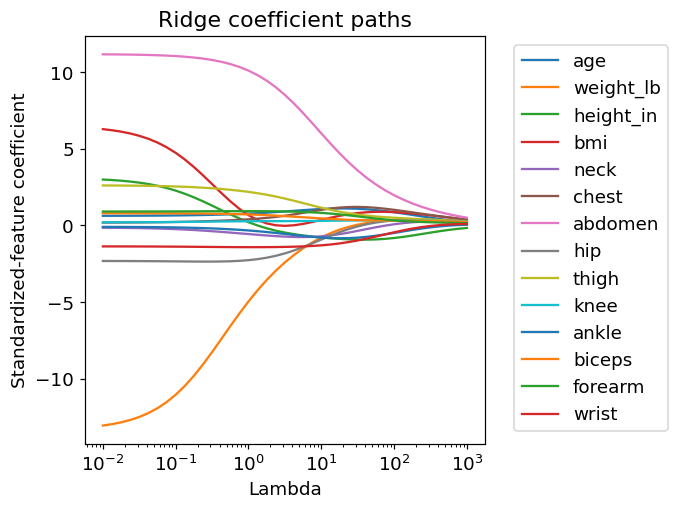

In [9]:
from sklearn.linear_model import Ridge

mu, sd         = X_train.mean(axis=0), X_train.std(axis=0, ddof=0)            # TODO: training-set mean and standard deviation of each measurement, shape (14,)
Z_train, Z_val = (X_train - mu) / sd, (X_val - mu) / sd            # TODO: standardised training and validation features

lambdas = np.logspace(-2, 3, 41)
# --- TODO: fit Ridge for every lambda; collect the validation RMSE and the weight vectors ---
val_rmse    = []                     # array, one entry per lambda
weights     = []                     # array of shape (len(lambdas), 14)

for lam in lambdas:
    model = Ridge(alpha=lam)
    model.fit(Z_train, y_train)

    val_rmse.append(rmse(y_val, model.predict(Z_val)))
    weights.append(model.coef_)

val_rmse = np.array(val_rmse)
weights = np.array(weights)

best_lambda = lambdas[np.argmin(val_rmse)]

assert Z_train is not None and np.allclose(Z_train.mean(axis=0), 0, atol=1e-8), "Standardise with the training statistics."
assert val_rmse is not None and len(val_rmse) == len(lambdas) and best_lambda is not None, "Fill in the sweep."
print(f"best lambda: {best_lambda:.3g}    validation RMSE there: {np.min(val_rmse):.2f}    (least squares: {rmse(y_val, pred_val_ols):.2f})")

# --- TODO: the two plots ---
plt.figure()
plt.plot(lambdas, val_rmse, marker="o")
plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Validation RMSE (percentage points)")
plt.title("Ridge validation error")
plt.show()

plt.figure()
for i, name in enumerate(measurements):
    plt.plot(lambdas, weights[:, i], label=name)

plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Standardized-feature coefficient")
plt.title("Ridge coefficient paths")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Answer 5** — Which $\lambda$ you chose and how; which weights the penalty shrinks first and why.



I chose λ = 1.3 because it gives the lowest validation RMSE (4.46 pp, against 4.51 pp for least squares). The curve is flat near the minimum and rises to 7.2 pp at λ = 1000, where every weight is shrunk almost to zero. On this split, ridge buys only a small improvement.


The penalty first shrinks the large weights of the collinear group weight/BMI/height. On the standardised scale, from λ = 0.01 to λ = 1.33: weight: −13.1 to −4.2, BMI: +6.3 to +0.4, and height: +3.0 to 0.0. BMI is a function of weight and height, and weight correlates 0.92 with BMI. Their large opposite-signed weights mostly cancel in the prediction. Shrinking them cuts the penalty λ‖w‖² a lot while barely raising the squared error, so the penalty removes them first. Abdomen carries strong, partly unique information (correlation 0.78 with body fat), so its weight shrinks least (11.2 → 9.8).

---
## 6 — A parsimonious model

A clinic would rather take three measurements than thirteen. Choose **at most three** of the 14
measurements, fit least squares on them, and compare the validation RMSE with the full model and
with ridge. Justify the choice with evidence from your notebook — correlations with the target,
correlations among the features, the weights — not with intuition alone.

> There is no single correct answer. A choice that is defended with evidence and evaluated honestly
> is correct; a choice that happens to score well is not.

In [10]:
# --- TODO: choose up to three measurements and fit least squares on them ---
chosen         =  ["abdomen", "wrist", "age"]                  # a list of 1 to 3 column names from `measurements`
small          = LinearRegression()
small.fit(X_train[:, [measurements.index(c) for c in chosen]], y_train)                  # the fitted model
pred_val_small = small.predict( X_val[:, [measurements.index(c) for c in chosen]])




assert chosen is not None and 1 <= len(chosen) <= 3 and all(c in measurements for c in chosen), "Choose 1 to 3 measurements."
assert pred_val_small is not None, "Fit the model and predict the validation set."
print(f"{chosen}: validation RMSE {rmse(y_val, pred_val_small):.2f}   "
      f"(full least squares {rmse(y_val, pred_val_ols):.2f}, ridge {np.min(val_rmse):.2f}, mean {baseline_rmse:.2f})")

['abdomen', 'wrist', 'age']: validation RMSE 4.28   (full least squares 4.51, ridge 4.46, mean 9.08)


**Answer 6** — Your choice of measurements and the evidence for it.





I went with the abdomen, wrist and age. The validation RMSE is 4.28 pp, better than full least squares (4.51), ridge (4.46) and the mean (9.08). I picked the abdomen since it has the highest correlation with body fat (0.78 on the training set) and by far the largest standardised weight in both least squares and ridge. I pciked the wrist since it is a size measure only moderately correlated with abdomen (0.64). It had a large negative weight in the full model (−1.42 pp/cm), and the sign stays negative across the ridge path. It measures skeletal frame rather than fat, so it corrects abdomen for body build. Adding it to abdomen lowers the validation RMSE from 4.63 to 4.25, the largest gain from any second feature I tried. I then pciked age because age is almost uncorrelated with the size measurements (0.16 with abdomen, 0.22 with wrist), so it carries different information and it has a positive correlation with body fat (0.23).

---
## 7 — The test set, once

Every decision has now been made on validation data: the data cleaning, $\lambda$, and the small
model. Refit each model on the **development set** — training and validation together — with its
chosen settings (standardise with the development set's statistics for ridge), and evaluate all of
them on the test set. Report, in one table:

| Model | Test RMSE | Test $R^2$ |
|---|---|---|
| predict the development-set mean | | |
| least squares, 14 measurements | | |
| ridge, $\lambda$ from section 5 | | |
| your model from section 6 | | |

and a plot of predicted against observed body fat on the test set for your preferred model. The test
set is not used again after this cell. If you change a model after seeing these numbers, the test
set is no longer a test set.

                         model  test RMSE  test R^2
      predict development mean      8.533    -0.000
least squares, 14 measurements      5.015     0.655
                         ridge      4.818     0.681
            three measurements      4.461     0.727


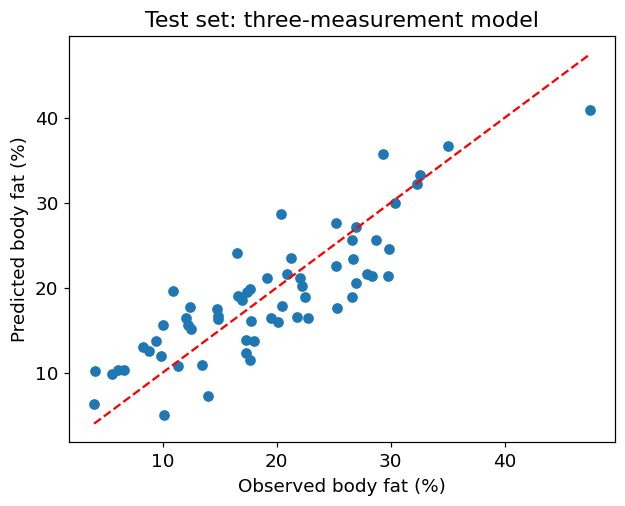

In [11]:
# --- TODO: refit each model on the development set and evaluate on the test set ---
results = X_dev_df = clean[measurements].iloc[
    data.index.get_indexer(clean.index)
] if False else None

dev_mean = y_dev.mean()

ols_dev = LinearRegression().fit(X_dev, y_dev)
pred_ols_test = ols_dev.predict(X_test)

mu_dev = X_dev.mean(axis=0)
sd_dev = X_dev.std(axis=0, ddof=0)
Z_dev = (X_dev - mu_dev) / sd_dev
Z_test = (X_test - mu_dev) / sd_dev

ridge_dev = Ridge(alpha=best_lambda).fit(Z_dev, y_dev)
pred_ridge_test = ridge_dev.predict(Z_test)

chosen_idx = [measurements.index(c) for c in chosen]
small_dev = LinearRegression().fit(X_dev[:, chosen_idx], y_dev)
pred_small_test = small_dev.predict(X_test[:, chosen_idx])

results = pd.DataFrame([
    {
        "model": "predict development mean",
        "test RMSE": rmse(y_test, np.full_like(y_test, dev_mean, dtype=float)),
        "test R^2": r_squared(y_test, np.full_like(y_test, dev_mean, dtype=float))
    },
    {
        "model": "least squares, 14 measurements",
        "test RMSE": rmse(y_test, pred_ols_test),
        "test R^2": r_squared(y_test, pred_ols_test)
    },
    {
        "model": "ridge",
        "test RMSE": rmse(y_test, pred_ridge_test),
        "test R^2": r_squared(y_test, pred_ridge_test)
    },
    {
        "model": "three measurements",
        "test RMSE": rmse(y_test, pred_small_test),
        "test R^2": r_squared(y_test, pred_small_test)
    }
])          # a DataFrame with the columns ["model", "test RMSE", "test R^2"] and four rows



assert results is not None and len(results) == 4, "Four rows: mean, least squares, ridge, your model."
print(results.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# --- TODO: predicted against observed on the test set, with the diagonal ---
plt.figure()
plt.scatter(y_test, pred_small_test)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color="red"
)
plt.xlabel("Observed body fat (%)")
plt.ylabel("Predicted body fat (%)")
plt.title("Test set: three-measurement model")
plt.show()

---
## 8 — Report

Write the report in the cell below, in at most 300 words, under these headings. It is read by someone
who has not seen the rest of the notebook.

1. **The task.** What a row of $X$ is, what $y$ is, and what population the data describe.
2. **Data decisions.** What you changed or removed before fitting, and why.
3. **Results.** The table of section 7, with one sentence of interpretation per row.
4. **Two weights.** Interpret two weights of the full model, with units, including one whose sign is
   opposite to its correlation with body fat.
5. **Limitations.** Who the model should not be applied to, and why; what the known data errors
   might have done to the weights.
6. **Recommendation.** Which measurements a clinic should take, and what error to expect.

### Report

**1. The task.**

A row of X is one man’s 14 clinic measurements including age, weight, height, BMI and ten circumferences. y is his body fat (%) from underwater weighing via Siri’s equation. The data are 251 men aged 22–81, measured at Brigham Young University.




**2. Data decisions.**
In case 42, the height (29.5 in) was corrected to 69.5 in, as implied by the mans BMI. For case 182 (0% body fat; his density implies −3.6%) was removed because the true value is unrecoverable. Density was excluded because body fat is computed from it, so it leaks the target (R² 0.98 vs 0.75).



**3. Results.**

table:

| Model | Test RMSE | Test $R^2$ |
|---|---|---|
| predict the development-set mean | | |
| least squares, 14 measurements | | |
| ridge, $\lambda$ from section 5 | | |
| your model from section 6 | | |


The mean is the floor any model must beat. The least squares cuts the error by 41% but overfits very slightly. The ridge’s shrinkage helps a little bit. The 3 measurements beat all 14.


**4. Two weights.**

For the abdomen, +1.07 percentage points of body fat per cm, with the other 13 measurements held fixed and it is the dominant predictor. For weight, −0.44 percentage points per lb, although weight correlates +0.61 with body fat. Among men with the same girths, height and BMI, extra weight is lean mass so it predicts less fat. The sign flips since weight is collinear with BMI, abdomen and hip (r ≈ 0.9).


**5. Limitations.**

This should not apply to women, children, or very muscular or very obese people because the data is men only, aged 22–81, from one centre. Cases 48, 76 and 96 have body fat inconsistent with their density by 4–17 pp and were kept; such errors add noise and can bias the weights.

**6. Recommendation.**

A clinc should take abdomen circumference and wrist circumference, and record age. Shpould expect a typical error of about +/- 4.5 percentage points: adequate for screening, not for precise body composition.


---
## 9 — AI use, submission, and the defense

### AI use statement

In the cell below, list the AI tools you used and what for — code, debugging, explanation, writing —
in two to five lines. The statement is not graded for its content; its absence costs credit.

**AI use statement** —

For the code in each section i had help from chatGPT and had claude define what I used. Calude was also used to help debug and check my understanding. The written respsinse were typed by me but I had Claude review them to make sure i was answering the questions fully.


### Submitting

**Due Tuesday, October 13, at 11:59 PM EST.**

1. `Runtime ▸ Restart session and run all`. Every cell must run without error, and every check must
   pass.
2. `File ▸ Download ▸ Download .ipynb`.
3. Rename the file to `YOUR-GITHUB-USERNAME_lab01.ipynb` and move it into the `checkins/` folder of
   your clone.
4. Commit in GitHub Desktop, push, and open a pull request.

Late notebooks are accepted for 48 hours with a 20% penalty on the notebook portion. The defense quiz
cannot be made up except for a documented excused absence (syllabus).

### The defense quiz — Wednesday, October 14, Meeting 10

Ten minutes, written, at the start of the meeting, closed-book: laptops closed, no notes, no AI tools.
You will not have your notebook in front of you, so know its contents before you arrive, including your
main results to about two significant figures. Five or six short questions about your own notebook,
each answerable in two or three sentences. The kinds of question to expect:

- why a step was necessary — why the features are standardised before ridge, why the test set is
  used once
- what a number means — your test RMSE, in its units, against the predict-the-mean baseline
- what a weight means, and why its sign can disagree with the feature's correlation with the target
- what would have happened under a different choice — if `density` had been kept, or if $\lambda$ had
  been chosen on the test set

Each question is scored 0, 1 or 2. Prepare by being able to explain every cell of your notebook
without looking at it.